In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

forecasts = pd.read_csv("../results/forecasts.csv")
data = pd.read_csv("../data/raw/data.csv")

# Baseline only
forecasts = forecasts[
    forecasts["model"] == "baseline"
].copy()

forecasts["period"] = pd.to_datetime(forecasts["period"])

# Convert raw YYYYMM dates
data["Period"] = pd.to_datetime(
    data["Period"].astype(str),
    format="%Y%m"
)

# Match the economic condition to the month being predicted
df = forecasts.merge(
    data[["Country", "Period", "NL-CONJCLK"]],
    left_on=["country", "period"],
    right_on=["Country", "Period"],
    how="left",
    validate="many_to_one"
)

assert df["NL-CONJCLK"].notna().all()

df["absolute_error"] = abs(
    df["actual"] - df["prediction"]
)

display(df.head(15))

,country,model,origin,period,horizon,actual,prediction,absolute error,Country,Period,NL-CONJCLK,absolute_error
0,Bulgaria,baseline,2020-12-01 00:00:00,2021-01-01,1,703.0,697.483846,5.516154,Bulgaria,2021-01-01,-0.20,5.516154
1,Bulgaria,baseline,2020-12-01 00:00:00,2021-03-01,3,728.0,610.036890,117.963110,Bulgaria,2021-03-01,-0.06,117.963110
2,Bulgaria,baseline,2020-12-01 00:00:00,2021-06-01,6,584.0,710.041258,126.041258,Bulgaria,2021-06-01,0.27,126.041258
3,Bulgaria,baseline,2021-01-01 00:00:00,2021-02-01,1,773.0,697.725539,75.274461,Bulgaria,2021-02-01,-0.13,75.274461
4,Bulgaria,baseline,2021-01-01 00:00:00,2021-04-01,3,578.0,416.045289,161.954711,Bulgaria,2021-04-01,0.09,161.954711
5,Bulgaria,baseline,2021-01-01 00:00:00,2021-07-01,6,535.0,740.899357,205.899357,Bulgaria,2021-07-01,0.43,205.899357
6,Bulgaria,baseline,2021-02-01 00:00:00,2021-03-01,1,728.0,618.570409,109.429591,Bulgaria,2021-03-01,-0.06,109.429591
7,Bulgaria,baseline,2021-02-01 00:00:00,2021-05-01,3,603.0,610.636913,7.636913,Bulgaria,2021-05-01,0.18,7.636913
8,Bulgaria,baseline,2021-02-01 00:00:00,2021-08-01,6,964.0,869.133172,94.866828,Bulgaria,2021-08-01,0.50,94.866828
9,Bulgaria,baseline,2021-03-01 00:00:00,2021-04-01,1,578.0,432.687937,145.312063,Bulgaria,2021-04-01,0.09,145.312063


In [18]:

df["business_cycle"] = np.where(
    df["NL-CONJCLK"] >= 0,
    "Favorable",
    "Unfavorable"
)

print(
    df.groupby("business_cycle")["origin"]
      .nunique()
)


business_cycle
Favorable      33
Unfavorable    35
Name: origin, dtype: int64


In [19]:

results = (
    df.groupby(
        ["country", "model", "horizon", "business_cycle"]
    )
    .agg(
        mae=("absolute_error", "mean"),
        total_error=("absolute_error", "sum"),
        total_actual=("actual", "sum"),
        n_forecasts=("actual", "size"),
    )
    .reset_index()
)

results["wape"] = (
    100 * results["total_error"] / results["total_actual"]
)

results = results.drop(
    columns=["total_error", "total_actual"]
)

print(results.round(2).to_string(index=False))

results.to_csv(
    "../results/business_cycle_metrics.csv",
    index=False
)


 country    model  horizon business_cycle    mae  n_forecasts  wape
Bulgaria baseline        1      Favorable 105.68           30 12.07
Bulgaria baseline        1    Unfavorable  74.67           30 10.46
Bulgaria baseline        3      Favorable 106.08           30 12.11
Bulgaria baseline        3    Unfavorable  99.88           28 14.02
Bulgaria baseline        6      Favorable 110.94           28 12.38
Bulgaria baseline        6    Unfavorable 119.79           27 16.83
  Poland baseline        1      Favorable 186.84           30  8.58
  Poland baseline        1    Unfavorable 216.74           30 12.33
  Poland baseline        3      Favorable 200.12           30  9.19
  Poland baseline        3    Unfavorable 288.10           28 16.68
  Poland baseline        6      Favorable 204.35           28  9.31
  Poland baseline        6    Unfavorable 325.06           27 18.94
 Romania baseline        1      Favorable 151.34           30 14.51
 Romania baseline        1    Unfavorable 142.30

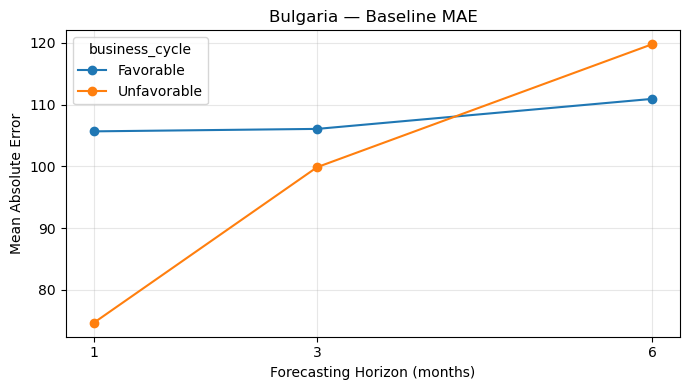

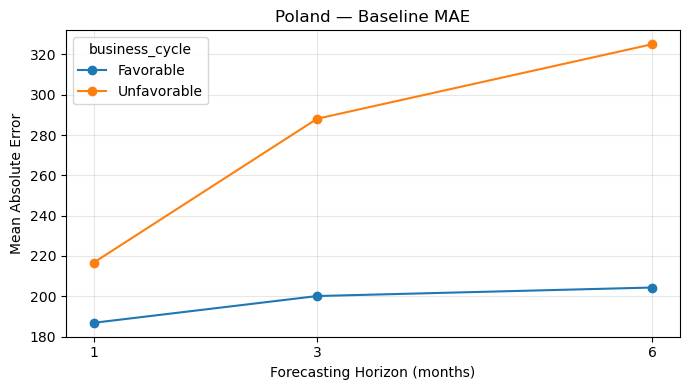

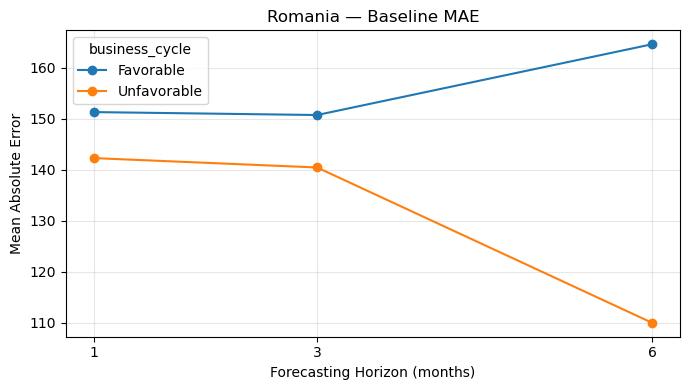

In [20]:
for country in results["country"].unique():

    subset = results[
        results["country"] == country
    ]

    pivot = subset.pivot(
        index="horizon",
        columns="business_cycle",
        values="mae"
    )

    ax = pivot.plot(
        kind="line",
        marker="o",
        figsize=(7, 4)
    )

    ax.set_title(f"{country} — Baseline MAE")
    ax.set_xlabel("Forecasting Horizon (months)")
    ax.set_ylabel("Mean Absolute Error")
    ax.set_xticks([1, 3, 6])
    ax.grid(alpha=0.3)

    plt.tight_layout()
    plt.show()


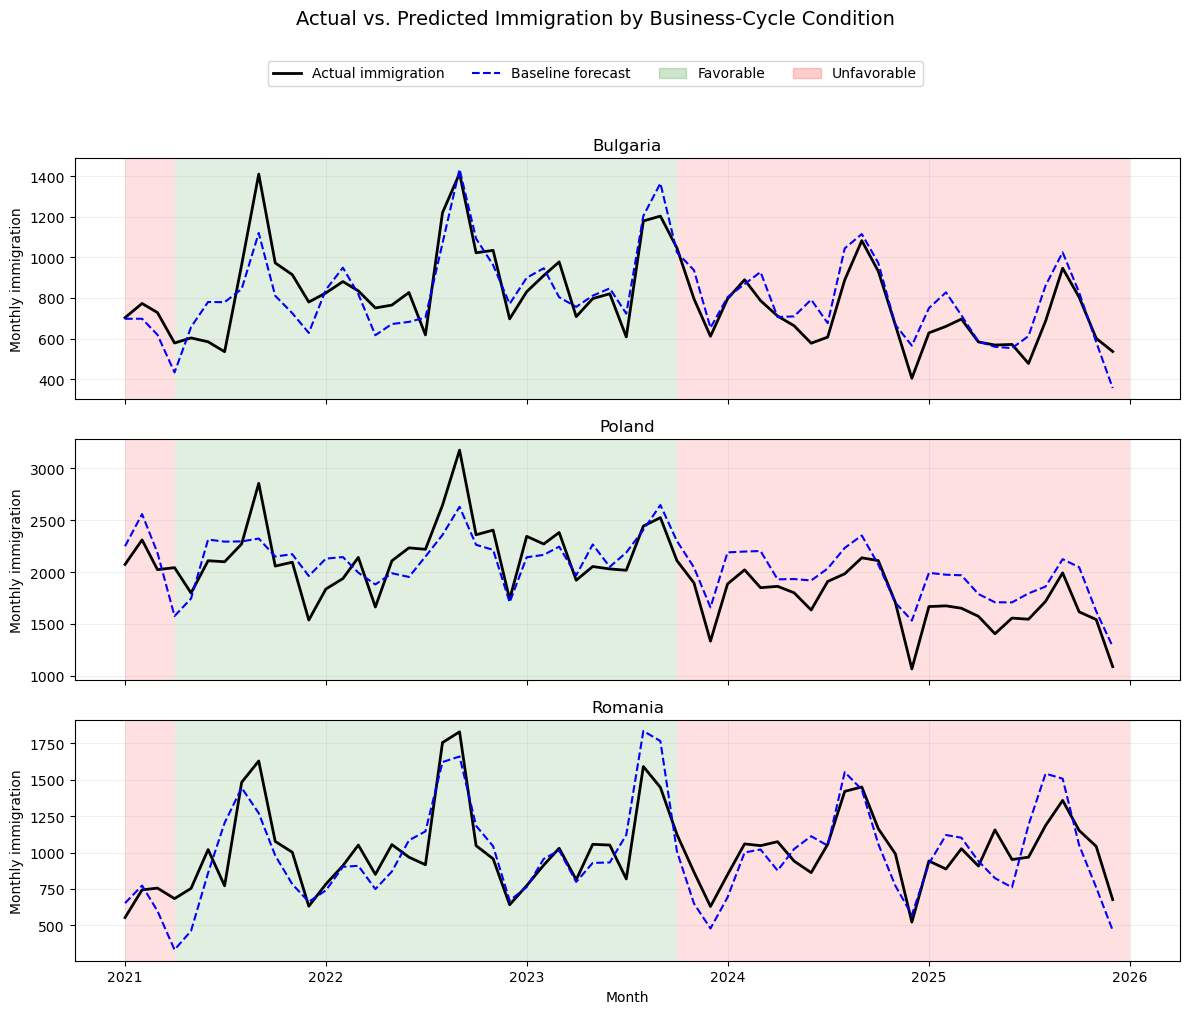

In [23]:
import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# One-month forecasts only
plot_df = df[df["horizon"] == 1].copy()

countries = ["Bulgaria", "Poland", "Romania"]

fig, axes = plt.subplots(
    nrows=3,
    ncols=1,
    figsize=(12, 10),
    sharex=True
)

for ax, country in zip(axes, countries):

    subset = (
        plot_df[plot_df["country"] == country]
        .sort_values("period")
    )

    # Business-cycle background shading
    for _, row in subset.iterrows():

        color = (
            "green"
            if row["business_cycle"] == "Favorable"
            else "red"
        )

        ax.axvspan(
            row["period"],
            row["period"] + pd.DateOffset(months=1),
            color=color,
            alpha=0.12,
            linewidth=0
        )

    # Actual immigration
    ax.plot(
        subset["period"],
        subset["actual"],
        color="black",
        linewidth=2,
        label="Actual immigration"
    )

    # Predicted immigration
    ax.plot(
        subset["period"],
        subset["prediction"],
        color="blue",
        linestyle="--",
        linewidth=1.5,
        label="Baseline forecast"
    )

    ax.set_title(country)
    ax.set_ylabel("Monthly immigration")
    ax.grid(alpha=0.2)

# Shared legend for the entire figure
legend_items = [
    plt.Line2D([0], [0], color="black", linewidth=2,
               label="Actual immigration"),
    plt.Line2D([0], [0], color="blue", linestyle="--",
               label="Baseline forecast"),
    Patch(color="green", alpha=0.2, label="Favorable"),
    Patch(color="red", alpha=0.2, label="Unfavorable")
]

fig.legend(
    handles=legend_items,
    loc="upper center",
    ncol=4,
    bbox_to_anchor=(0.5, 0.965)
)

fig.suptitle(
    "Actual vs. Predicted Immigration by Business-Cycle Condition",
    fontsize=14,
    y=1.01
)

axes[-1].set_xlabel("Month")

plt.tight_layout(rect=[0, 0, 1, 0.93])

# Save for the Technical Report
plt.savefig(
    "../results/business_cycle_forecasts.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()